In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

In [9]:
image = cv2.imread('/content/apple.webp')

In [10]:
image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

In [11]:
gray_image = cv2.cvtColor(image, cv2.COLOR_RGB2GRAY)

In [12]:
image_float = gray_image.astype(np.float32)

In [13]:
laplacian_mask = np.array([
    [0, -1, 0],
    [-1, 4, -1],
    [0, -1, 0]
], dtype=np.float32)

In [14]:
laplacian_response = cv2.filter2D(
    image_float, cv2.CV_32F, laplacian_mask
)

In [15]:
laplacian = np.clip(
    image_float + laplacian_response, 0, 255
).astype(np.uint8)

In [16]:
enhanced_mask = np.array([
    [0, -1, 0],
    [-1, 5, -1],
    [0, -1, 0]
], dtype=np.float32)

enhanced_laplacian = cv2.filter2D(
    gray_image, -1, enhanced_mask
)

In [17]:
A = 1.5

# Blur the original image
blurred_image = cv2.GaussianBlur(
    gray_image, (5, 5), 1.0
)

In [18]:
high_boost = np.clip(
    A * image_float - blurred_image.astype(np.float32),
    0, 255
).astype(np.uint8)

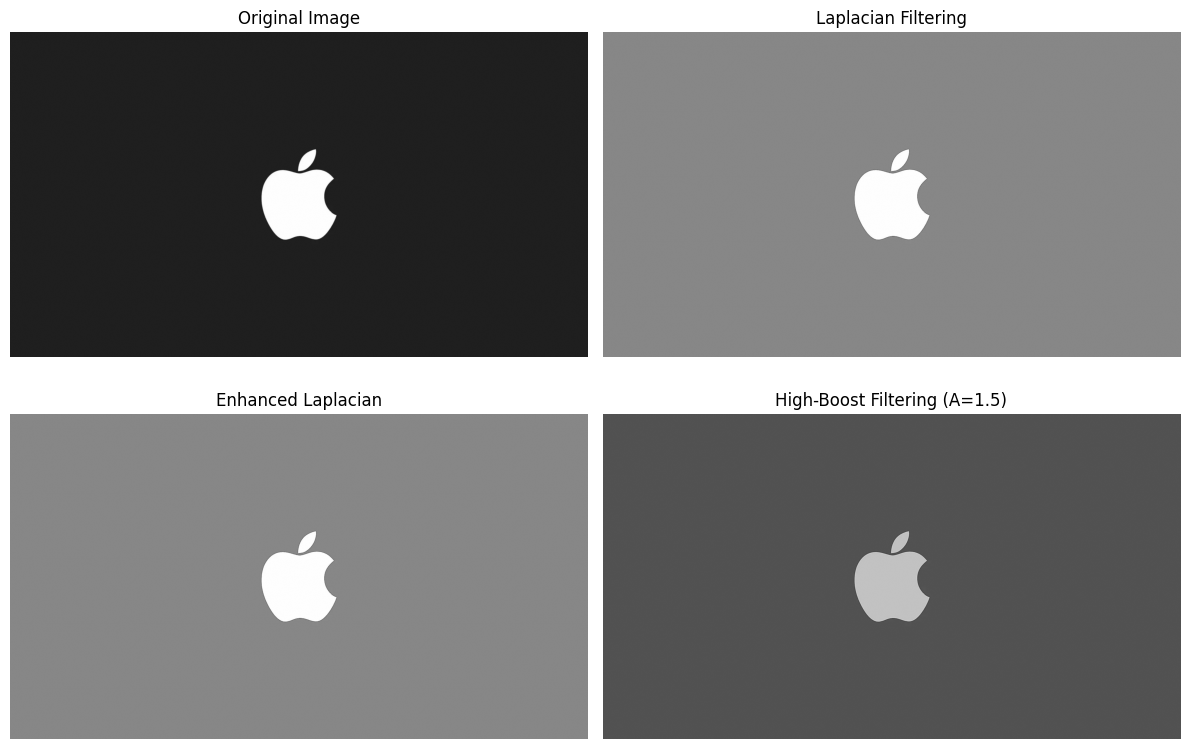

In [19]:
plt.figure(figsize=(12, 8))

plt.subplot(2, 2, 1)
plt.imshow(gray_image, cmap='gray')
plt.title('Original Image')
plt.axis('off')

plt.subplot(2, 2, 2)
plt.imshow(laplacian, cmap='gray')
plt.title('Laplacian Filtering')
plt.axis('off')

plt.subplot(2, 2, 3)
plt.imshow(enhanced_laplacian, cmap='gray')
plt.title('Enhanced Laplacian')
plt.axis('off')

plt.subplot(2, 2, 4)
plt.imshow(high_boost, cmap='gray')
plt.title('High-Boost Filtering (A=1.5)')
plt.axis('off')

plt.tight_layout()
plt.show()